# Análise Exploratória (EDA) — Empório da Música

Análise exploratória das tabelas operacionais da **Empório da Música** (`data/*.csv`) com o objetivo de inspecionar a estrutura, tipagem, valores ausentes, duplicidades e regras de negócio antes de disponibilizar o banco de dados para o agente Text-to-SQL.

## Visão Geral

A base operacional é composta por seis tabelas relacionais:
- `categories` (9 registros): categorias de instrumentos musicais.
- `products` (65 registros): catálogo de produtos com preços, estoque, status e especificações em JSON.
- `promotions` (25 registros): histórico de campanhas promocionais e descontos ativos.
- `customers` (50 registros): cadastro de clientes (nome, telefone, e-mail e cidade).
- `orders` (20 registros): cabeçalho dos pedidos com status, forma de pagamento, rastreio e notas.
- `order_items` (22 registros): itens associados a cada pedido.

In [23]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
DATA_DIR = "../data" 

Bibliotecas carregadas e diretório de dados configurado (`../data`).

## 1. Carregar as tabelas da base

In [24]:
df_categories = pd.read_csv(os.path.join(DATA_DIR, "desafio_tecnico_ai_eng - categories.csv"))
df_products = pd.read_csv(os.path.join(DATA_DIR, "desafio_tecnico_ai_eng - products.csv"))
df_promotions = pd.read_csv(os.path.join(DATA_DIR, "desafio_tecnico_ai_eng - promotions.csv"))
df_customers = pd.read_csv(os.path.join(DATA_DIR, "desafio_tecnico_ai_eng - customers.csv"))
df_orders = pd.read_csv(os.path.join(DATA_DIR, "desafio_tecnico_ai_eng - orders.csv"))
df_order_items = pd.read_csv(os.path.join(DATA_DIR, "desafio_tecnico_ai_eng - order_items.csv"))

print("Tabelas carregadas com sucesso!")

Tabelas carregadas com sucesso!


Os seis arquivos CSV foram carregados em DataFrames independentes para inspeção estrutural.

### 1.1 Exploração inicial (`info`)

In [25]:
print(">> Tabela de categorias:")
display(df_categories.info())

print("\n>> Tabela de produtos:")
display(df_products.info())

print("\n>> Tabela de promoções:")
display(df_promotions.info())

print("\n>> Tabela de clientes:")
display(df_customers.info())

print("\n>> Tabela de pedidos:")
display(df_orders.info())

print("\n>> Tabela de itens de pedido:")
display(df_order_items.info())

>> Tabela de categorias:
<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   category_id  9 non-null      int64
 1   name         9 non-null      str  
 2   description  9 non-null      str  
dtypes: int64(1), str(2)
memory usage: 1015.0 bytes


None


>> Tabela de produtos:
<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      65 non-null     int64  
 1   price_brl       65 non-null     float64
 2   name            65 non-null     str    
 3   category_id     65 non-null     int64  
 4   description     65 non-null     str    
 5   stock_quantity  65 non-null     int64  
 6   status          65 non-null     str    
 7   specs           65 non-null     str    
 8   created_at      65 non-null     str    
dtypes: float64(1), int64(3), str(5)
memory usage: 23.5 KB


None


>> Tabela de promoções:
<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   promotion_id      25 non-null     int64
 1   product_id        25 non-null     int64
 2   discount_percent  25 non-null     int64
 3   description       25 non-null     str  
 4   is_active         25 non-null     int64
dtypes: int64(4), str(1)
memory usage: 1.5 KB


None

... (2 outputs left out)


>> Tabela de pedidos:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            20 non-null     int64  
 1   customer_id         20 non-null     int64  
 2   order_date          20 non-null     str    
 3   status              20 non-null     str    
 4   total_brl           20 non-null     float64
 5   payment_method      20 non-null     str    
 6   tracking_code       8 non-null      str    
 7   estimated_delivery  8 non-null      str    
 8   notes               4 non-null      str    
dtypes: float64(1), int64(2), str(6)
memory usage: 2.4 KB


None


>> Tabela de itens de pedido:
<class 'pandas.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   order_id    22 non-null     int64
 1   quantity    22 non-null     int64
 2   product_id  22 non-null     int64
dtypes: int64(3)
memory usage: 660.0 bytes


None

A inspeção de tipos e contagens mostra que `categories`, `products`, `promotions`, `customers` e `order_items` estão 100% preenchidas (sem valores nulos). Na tabela `orders`, apenas as colunas `tracking_code` (8 não-nulos), `estimated_delivery` (8 não-nulos) e `notes` (4 não-nulos) apresentam valores ausentes.

### 1.2 Visualizar amostras das tabelas (`head`)

In [26]:
print(">> Categorias:")
display(df_categories.head())

print(">> Produtos:")
display(df_products.head(3))

print(">> Promoções:")
display(df_promotions.head())

print(">> Clientes:")
display(df_customers.head())

print(">> Pedidos:")
display(df_orders.head())

print(">> Itens de Pedido:")
display(df_order_items.head())

>> Categorias:


,category_id,name,description
0,1,Guitarras,"Guitarras elétricas de todos os estilos, do ro..."
1,2,Baixos,Baixos elétricos e acústicos para todas as for...
2,3,Baterias e Percussão,"Baterias acústicas, eletrônicas e peças avulsa..."
3,4,Teclados e Pianos,"Pianos digitais, sintetizadores, arranjadores ..."
4,5,Violões,"Violões clássicos, folk e eletroacústicos"


>> Produtos:


,product_id,price_brl,name,category_id,description,stock_quantity,status,specs,created_at
0,81,599.9,Yamaha C40 Nylon Natural,5,Violão clássico com tampo em Spruce e fundo/la...,12,active,"{""top"":""Spruce"",""back_sides"":""Meranti"",""neck"":...",2021-03-15
1,82,849.0,Yamaha C70 Nylon Natural,5,Violão clássico de nível intermediário com tam...,8,active,"{""top"":""Spruce Sólido"",""back_sides"":""Nato"",""ne...",2021-06-20
2,83,429.9,Tagima Memphis AC-39 Nylon Natural,5,"Violão clássico com cordas de nylon, perfeito ...",15,active,"{""top"":""Linden"",""back_sides"":""Linden"",""neck"":""...",2020-08-10


>> Promoções:


,promotion_id,product_id,discount_percent,description,is_active
0,1,102,10,Black Friday,0
1,2,110,15,Liquidação de Inverno,0
2,3,122,20,Queima de Estoque,0
3,4,95,12,Oferta Especial,0
4,5,126,25,Aniversário da Loja,0


... (2 outputs left out)

>> Pedidos:


,order_id,customer_id,order_date,status,total_brl,payment_method,tracking_code,estimated_delivery,notes
0,1,3,2025-10-15,delivered,11499.0,pix,BRAB1234567BR,2025-10-25,NaN
1,2,7,2025-11-02,delivered,5999.0,credit_6x,BRCX9876543BR,2025-11-15,NaN
2,3,12,2025-11-20,delivered,3450.0,credit_12x,BRDZ4561230BR,2025-12-05,NaN
3,4,1,2025-12-10,delivered,799.9,boleto,BRQM7890123BR,2025-12-22,NaN
4,5,5,2026-01-05,delivered,4599.0,pix,BRTP3456789BR,2026-01-18,NaN


>> Itens de Pedido:


,order_id,quantity,product_id
0,1,1,93
1,2,1,94
2,3,2,130
3,4,1,96
4,5,1,97


As amostras confirmam o relacionamento entre as chaves primárias e estrangeiras (`category_id`, `product_id`, `customer_id`, `order_id`), além do formato JSON armazenado na coluna `specs` de `products`.

### 1.3 Estatísticas descritivas (`describe`)

In [27]:
print(">> Descrição: Produtos")
display(df_products.describe())

print(">> Descrição: Promoções")
display(df_promotions.describe())

print(">> Descrição: Pedidos")
display(df_orders.describe())

>> Descrição: Produtos


,product_id,price_brl,category_id,stock_quantity
count,65.00000,65.000000,65.000000,65.000000
mean,113.00000,3671.812308,5.292308,6.415385
std,18.90767,4709.028077,2.389581,3.896683
min,81.00000,159.900000,1.000000,0.000000
25%,97.00000,689.000000,5.000000,3.000000
50%,113.00000,1299.000000,5.000000,6.000000
75%,129.00000,4599.000000,5.000000,9.000000
max,145.00000,19567.000000,9.000000,15.000000


>> Descrição: Promoções


,promotion_id,product_id,discount_percent,is_active
count,25.000000,25.000000,25.000000,25.000000
mean,13.000000,111.160000,17.880000,0.160000
std,7.359801,16.466329,8.959725,0.374166
min,1.000000,90.000000,5.000000,0.000000
25%,7.000000,96.000000,10.000000,0.000000
50%,13.000000,110.000000,15.000000,0.000000
75%,19.000000,125.000000,22.000000,0.000000
max,25.000000,140.000000,40.000000,1.000000


>> Descrição: Pedidos


,order_id,customer_id,total_brl
count,20.00000,20.000000,20.000000
mean,10.50000,9.050000,3343.470000
std,5.91608,5.276313,3605.504529
min,1.00000,1.000000,159.900000
25%,5.75000,4.750000,452.400000
50%,10.50000,8.500000,1574.500000
75%,15.25000,13.250000,6374.000000
max,20.00000,18.000000,11499.000000


- Em `products`, os preços (`price_brl`) variam de R\$ 159,90 a R\$ 19.567,00 (média de R\$ 3.309,50), e o estoque (`stock_quantity`) varia de 0 a 15 unidades.
- Em `promotions`, os descontos variam de 5% a 40%, mas a média de `is_active` é de apenas 0,16 (indicando que a maioria das promoções está inativa).
- Em `orders`, os valores totais (`total_brl`) variam de R\$ 159,90 a R\$ 11.499,00.

## 2. Análise de Valores Nulos e Duplicidades

In [28]:
print(">> Nulos em Pedidos (orders):")
display(df_orders.isnull().sum())

print("\n>> Relação entre status do pedido e preenchimento de rastreio/notas:")
display(df_orders.groupby("status")[["tracking_code", "estimated_delivery", "notes"]].count())

print("\n>> Linhas inteiramente duplicadas por tabela:")
for nome, df in [
    ("categories", df_categories),
    ("products", df_products),
    ("promotions", df_promotions),
    ("customers", df_customers),
    ("orders", df_orders),
    ("order_items", df_order_items),
]:
    print(f"{nome}: {df.duplicated().sum()} duplicadas")

>> Nulos em Pedidos (orders):


order_id               0
customer_id            0
order_date             0
status                 0
total_brl              0
payment_method         0
tracking_code         12
estimated_delivery    12
notes                 16
dtype: int64


>> Relação entre status do pedido e preenchimento de rastreio/notas:


,tracking_code,estimated_delivery,notes
status,,,
cancelled,0,0,4
confirmed,0,0,0
delivered,7,7,0
pending,0,0,0
shipped,1,1,0



>> Linhas inteiramente duplicadas por tabela:
categories: 0 duplicadas
products: 0 duplicadas
promotions: 0 duplicadas
customers: 0 duplicadas
orders: 0 duplicadas
order_items: 0 duplicadas


Os valores nulos em `orders` seguem a regra operacional do negócio:
- `tracking_code` e `estimated_delivery` só existem para os **8 pedidos enviados ou entregues** (`shipped` = 1, `delivered` = 7). Pedidos `pending`, `confirmed` e `cancelled` não possuem rastreamento.
- A coluna `notes` está preenchida exclusivamente nos **4 pedidos cancelados** (`cancelled`), registrando o motivo do cancelamento.

### 2.1 Verificação de Homônimos e E-mails Duplicados em Clientes

In [29]:
print(">> Clientes com o mesmo e-mail:")
display(df_customers[df_customers.duplicated(subset=["email"], keep=False)])

print("\n>> Clientes com sobrenomes/nomes semelhantes (Bruno Martins e Diego Castro):")
display(df_customers[df_customers["name"].str.contains("Bruno|Diego", case=False)])

>> Clientes com o mesmo e-mail:


,customer_id,name,phone,email,city
10,11,Bruno Carvalho Martins,(67) 98543-2109,bruno.martins@jmail.com,Três Lagoas
42,43,Bruno Martins,(67) 99456-3456,bruno.martins@jmail.com,Três Lagoas



>> Clientes com sobrenomes/nomes semelhantes (Bruno Martins e Diego Castro):


,customer_id,name,phone,email,city
10,11,Bruno Carvalho Martins,(67) 98543-2109,bruno.martins@jmail.com,Três Lagoas
12,13,Diego Fernandes Castro,(67) 98210-9876,diego.castro@coldmail.com,Campo Grande
26,27,Bruno Carvalho,(67) 99999-0000,bruno.carvalho@inlook.com,Dourados
42,43,Bruno Martins,(67) 99456-3456,bruno.martins@jmail.com,Três Lagoas
46,47,Diego Castro,(67) 99890-7890,diego.castro@jmail.com,Dourados


Foram identificados casos importantes em `customers`:
1. O e-mail `bruno.martins@jmail.com` aparece duplicado em dois registros distintos de Três Lagoas: `customer_id = 11` (*Bruno Carvalho Martins*) e `customer_id = 43` (*Bruno Martins*).
2. Há também dois clientes chamados Diego Castro (`customer_id = 13`, *Diego Fernandes Castro* de Campo Grande, e `customer_id = 47`, *Diego Castro* de Dourados).
3. Portanto, nas consultas de pedidos, é fundamental desambiguar pelo `order_id`, `customer_id` ou nome completo.

## 3. Análise do Catálogo: Categorias, Status e Estoque

,category_id,categoria,qtd_produtos
0,1,Guitarras,5
1,2,Baixos,4
2,3,Baterias e Percussão,3
3,4,Teclados e Pianos,3
4,5,Violões,35
5,6,Instrumentos de Sopro (Madeiras),0
6,7,Instrumentos de Sopro (Metais),0
7,8,Cordas Orquestrais,0
8,9,Ukuleles,15


C:\Users\Cesar Yuri\AppData\Local\Temp\ipykernel_14652\2769096658.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_counts, x="qtd_produtos", y="categoria", palette="Blues_r")


Text(0, 0.5, 'Categoria')

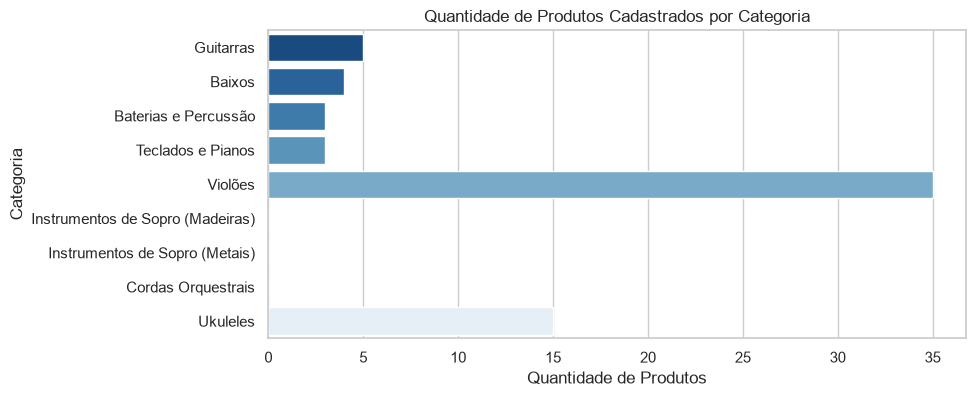

In [30]:
cat_counts = (
    df_categories.merge(df_products, on="category_id", how="left")
    .groupby(["category_id", "name_x"], as_index=False)["product_id"]
    .count()
    .rename(columns={"name_x": "categoria", "product_id": "qtd_produtos"})
)
display(cat_counts)

plt.figure(figsize=(9, 4))
sns.barplot(data=cat_counts, x="qtd_produtos", y="categoria", palette="Blues_r")
plt.title("Quantidade de Produtos Cadastrados por Categoria")
plt.xlabel("Quantidade de Produtos")
plt.ylabel("Categoria")

Observa-se que **3 das 9 categorias cadastradas não possuem nenhum produto na tabela `products`**:
- Categoria 6: *Instrumentos de Sopro (Madeiras)* (0 produtos)
- Categoria 7: *Instrumentos de Sopro (Metais)* (0 produtos)
- Categoria 8: *Cordas Orquestrais* (0 produtos)

O catálogo atual concentra-se em **Violões** (35 itens), **Ukuleles** (15 itens), **Guitarras** (5 itens), **Baixos** (4 itens), **Baterias** (3 itens) e **Teclados** (3 itens).

In [31]:
print(">> Contagem de produtos por status:")
display(df_products["status"].value_counts())

print("\n>> Produtos fora de estoque (stock_quantity == 0) ou status diferente de 'active':")
anomalias_status = df_products[(df_products["stock_quantity"] == 0) | (df_products["status"] != "active")][
    ["product_id", "name", "category_id", "price_brl", "stock_quantity", "status", "created_at"]
]
display(anomalias_status)

>> Contagem de produtos por status:


status
active          62
discontinued     2
coming_soon      1
Name: count, dtype: int64


>> Produtos fora de estoque (stock_quantity == 0) ou status diferente de 'active':


,product_id,name,category_id,price_brl,stock_quantity,status,created_at
15,96,Giannini GF-3D Dreadnought Sunburst,5,799.9,0,active,2020-02-28
32,113,Shelby SN-7C 7 Cordas Nylon Natural,5,749.0,0,discontinued,2020-03-05
49,130,Kala KA-ABP-CTG Barítono Cedar,9,1749.0,2,coming_soon,2025-05-15
56,136,Ibanez Bass 2X Electric Bass,2,441.0,13,discontinued,2021-08-07


Quatro produtos exigem atenção especial conforme a **Seção 7.3 do Manual de Políticas**:
1. `product_id = 96` (*Giannini GF-3D Dreadnought Sunburst*): está com `status = 'active'`, mas **`stock_quantity = 0`** (fora de estoque temporariamente).
2. `product_id = 113` (*Shelby SN-7C 7 Cordas Nylon Natural*): `status = 'discontinued'` e `stock_quantity = 0`.
3. `product_id = 136` (*Ibanez Bass 2X Electric Bass*): está com **`status = 'discontinued'`**, porém apresenta **`stock_quantity = 13`**. Se uma query filtrar apenas `stock_quantity > 0` sem verificar `status = 'active'`, recomendará indevidamente um item descontinuado.
4. `product_id = 130` (*Kala KA-ABP-CTG Barítono Cedar*): está com `status = 'coming_soon'` (`stock_quantity = 2`), não estando disponível para pronta-entrega imediata.

### 3.1 Inconsistências entre Nome, Descrição e Especificações (`product_id` 135 a 144)

In [32]:
print(">> Inspeção dos produtos das categorias 2 (Baixos), 3 (Baterias) e 4 (Teclados):")
df_inconsistentes = df_products[df_products["category_id"].isin([2, 3, 4])][
    ["product_id", "category_id", "name", "description", "specs", "status", "stock_quantity"]
]
display(df_inconsistentes)

>> Inspeção dos produtos das categorias 2 (Baixos), 3 (Baterias) e 4 (Teclados):


,product_id,category_id,name,description,specs,status,stock_quantity
55,135,2,Music Man Bass 1X Electric Bass,Contrabaixo elétrico Fender Jazz Bass com corp...,"{""body"": ""Ash"", ""neck"": ""Maple"", ""strings"": ""4...",active,9
56,136,2,Ibanez Bass 2X Electric Bass,Contrabaixo Precision de 4 cordas com captação...,"{""body"": ""Ash"", ""neck"": ""Maple"", ""strings"": ""4...",discontinued,13
57,137,2,Yamaha Bass 3X Electric Bass,Contrabaixo ativo de 5 cordas Ibanez com equal...,"{""body"": ""Ash"", ""neck"": ""Maple"", ""strings"": ""4...",active,11
58,138,2,Music Man Bass 4X Electric Bass,Contrabaixo elétrico Music Man StingRay com ca...,"{""body"": ""Ash"", ""neck"": ""Maple"", ""strings"": ""4...",active,9
59,139,3,Bateria Acústica Yamaha Kit 1 Studio,Bateria acústica Pearl Export com cascos em Po...,"{""shells"": ""Maple"", ""pieces"": ""5"", ""hardware"":...",active,8
60,140,3,Bateria Acústica Pearl Kit 2 Studio,Bateria acústica Tama com cascos 100% Birch e ...,"{""shells"": ""Maple"", ""pieces"": ""5"", ""hardware"":...",active,7
61,141,3,Bateria Acústica Yamaha Kit 3 Studio,Bateria acústica Yamaha Stage Custom com bumbo...,"{""shells"": ""Maple"", ""pieces"": ""5"", ""hardware"":...",active,8
62,142,4,Teclado Sintetizador Korg Synth 1 Pro,Sintetizador workstation Roland com 88 teclas ...,"{""keys"": ""61"", ""type"": ""Synthesizer"", ""polypho...",active,2
63,143,4,Teclado Sintetizador Nord Synth 2 Pro,Piano de palco Nord Stage com seções independe...,"{""keys"": ""61"", ""type"": ""Synthesizer"", ""polypho...",active,3
64,144,4,Teclado Sintetizador Roland Synth 3 Pro,Teclado arranjador Yamaha com 61 teclas sensit...,"{""keys"": ""61"", ""type"": ""Synthesizer"", ""polypho...",active,8


Nos registros de `product_id` **135 a 144** (Baixos, Baterias e Teclados), há divergências claras entre o nome do produto (`name`), a descrição (`description`) e o JSON `specs`:
- `product_id = 135`: Nome é **Music Man Bass 1X**, mas a descrição diz **Fender Jazz Bass** com corpo em *Alder* e o `specs` indica `"body": "Ash"`.
- `product_id = 137`: Nome é **Yamaha Bass 3X**, mas a descrição diz **5 cordas Ibanez** e o `specs` indica `"strings": "4"`.
- `product_id = 139`: Nome é **Bateria Acústica Yamaha Kit 1**, mas a descrição cita **Pearl Export**.
- `product_id = 140`: Nome é **Bateria Acústica Pearl Kit 2**, mas a descrição cita **Tama**.
- `product_id = 142`: Nome é **Teclado Sintetizador Korg Synth 1 Pro**, mas a descrição cita **Roland com 88 teclas** e o `specs` indica `"keys": "61"`.
- `product_id = 144`: Nome é **Teclado Sintetizador Roland Synth 3 Pro**, mas a descrição cita **Yamaha**.

Isso indica erro de carga/template na tabela bruta e pode causar alucinação caso o agente faça buscas por marca na coluna `description`.

## 4. Análise de Promoções (`promotions.csv`)

In [33]:
print(">> Contagem de promoções ativas vs. inativas:")
display(df_promotions["is_active"].value_counts())

print("\n>> Promoções ATIVAS no sistema (is_active == 1):")
promos_ativas = df_promotions[df_promotions["is_active"] == 1].merge(
    df_products[["product_id", "name", "price_brl", "stock_quantity", "status"]],
    on="product_id",
    how="left"
)
promos_ativas["preco_promocional_brl"] = (
    promos_ativas["price_brl"] * (1 - promos_ativas["discount_percent"] / 100.0)
).round(2)
display(promos_ativas)

print("\n>> Produtos com múltiplas entradas na tabela de promoções:")
display(df_promotions.groupby("product_id").size().loc[lambda s: s > 1])

>> Contagem de promoções ativas vs. inativas:


is_active
0    21
1     4
Name: count, dtype: int64


>> Promoções ATIVAS no sistema (is_active == 1):


,promotion_id,product_id,discount_percent,description,is_active,name,price_brl,stock_quantity,status,preco_promocional_brl
0,12,127,10,Oferta Especial,1,Kalani KAL-700T Tenor Natural,359.0,11,active,323.10
1,14,121,20,Desconto Exclusivo,1,Ohana CK-20 Concert Natural,549.0,6,active,439.20
2,19,90,18,Desconto Exclusivo,1,Crafter HT-100 Folk Aço Natural,2399.0,3,active,1967.18
3,24,94,8,Desconto Exclusivo,1,Taylor 110e Dreadnought Natural,5999.0,4,active,5519.08



>> Produtos com múltiplas entradas na tabela de promoções:


product_id
93    2
96    2
99    2
dtype: int64

Das 25 promoções registradas na tabela:
- Apenas **4 estão ativas (`is_active = 1`)**: `product_id` **90** (18% off), **94** (8% off), **121** (20% off) e **127** (10% off).
- As outras **21 estão expiradas (`is_active = 0`)**, e alguns produtos (`93`, `96`, `99`) possuem mais de uma promoção histórica.
- Conforme a Seção 6.2 do Manual, **promoções não são cumulativas com o desconto de 5% do PIX**, e o preço promocional deve sempre ser informado junto ao preço original e ao percentual de desconto.

## 5. Conclusão e Diretrizes para o Banco SQLite do Agente

A análise exploratória evidencia que, para garantir respostas precisas e evitar alucinações no Text-to-SQL:
1. **Disponibilidade real**: Um produto só está disponível para compra imediata quando `status = 'active'` **e** `stock_quantity > 0`.
2. **Promoções vigentes**: Consultas de desconto devem filtrar `is_active = 1` (ou informar explicitamente quando uma promoção histórica estiver encerrada, com `is_active = 0`).
3. **Criação de Views auxiliares no SQLite**:
   - Criar uma view de catálogo (`vw_catalogo_produtos`) que já relacione `products`, `categories` e a promoção ativa (`promotions` com `is_active = 1`), calculando `preco_promocional` e `preco_pix` (sem acumular descontos) e expondo o status real de estoque.
   - Criar uma view de pedidos (`vw_pedidos_detalhados`) unindo `orders`, `customers`, `order_items` e `products` para simplificar consultas de rastreamento, status e verificação de prazos de troca/devolução.